# Лабораторная работа 4. Полевой транзистор Шоттки на гетероструктуре GaAs/AlGaAs/GaAs

Задача — подобрать структуру, в которой одной лишь глубиной выемки под затвор на одной
пластине получаются и нормально открытые, и нормально закрытые транзисторы. Глубину
задаёт тонкий стоп-слой AlGaAs: селективное травление останавливается на нём с
точностью до монослоя.

Задания:
1. выходные ВАХ нормально открытого транзистора при нескольких напряжениях на затворе;
2. передаточные ВАХ при Vd = 2 В для шести расстояний h от затвора до стоп-слоя;
3. передаточная ВАХ нормально закрытого транзистора и пороговое напряжение;
4. выходные ВАХ нормально закрытого транзистора.

Расчёт идёт в ISE внутри Windows XP, управление — по telnet (`tools/xp.py`). Без
виртуальной машины выполняются все ячейки, кроме помеченных `RUN`: тогда используются
уже выгруженные файлы из `ise/`.

In [1]:
import sys, os, re, time
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "tools")) and ROOT != "/":
    ROOT = os.path.dirname(ROOT)
sys.path.insert(0, os.path.join(ROOT, "tools"))
LAB = os.path.join(ROOT, "Lab4_MESFET_GaAs")
sys.path.insert(0, LAB)
import numpy as np
from IPython.display import Image, display
import lab4_files as L

RUN = False                  # True — пересчитать в ISE, False — взять готовые файлы из ise/
WORK = r"C:\tcad\L4"         # папка внутри Windows
ISE = os.path.join(LAB, "ise")
os.chdir(ISE)
if RUN:
    import xp, put
print(os.getcwd())

/Users/phoenix/Documents/MIET/labs_modelling/Nanostructure_Modelling_Course_MIET_2026/Lab4_MESFET_GaAs/ise


In [2]:
# ---- ВАРИАНТ ----
VARIANT = 2
H4 = 0.02            # толщина слоя S4 под стоп-слоем, мкм
N4 = 3.0e+17         # легирование слоя S4, 1/см3
H_OPEN = 0.05        # h для задания 1 (нормально открытый), мкм
H_CLOSED = 0.01      # h для заданий 3 и 4 (нормально закрытый), мкм
# -----------------
H_SCAN = (0.05, 0.04, 0.03, 0.02, 0.01, 0.0)     # задание 2 — у всех вариантов
VG_OPEN = (0.8, 0.0, -0.8, -1.6, -2.4)            # задание 1
VG_CLOSED = (0.0, 0.2, 0.4, 0.6, 0.8)             # задание 4

## 1. Структура, сетка и легирование

Слои сверху вниз (ось y — вглубь, мкм), x — 0…15: исток 0…5, канал 5…10, сток 10…15.

| слой | глубина | материал, легирование, 1/см³ |
|---|---|---|
| S8a, S8b | 0 … 0.1 | GaAs, 1e18 |
| S7 | 0.1 … 0.3 | GaAs, 4e17; выемка под затвор до глубины 0.3 − h |
| S6 | 0.3 … 0.301 | GaAs, 1e14 |
| S5 | 0.301 … 0.304 | AlGaAs (x = 1), стоп-слой, 1.5e18 |
| S4 | 0.304 … 0.304 + h₄ | GaAs, N₄ |
| S3 | … + 0.006 | GaAs, 7e17 |
| S2 | … 1.05 | GaAs, 1e14 |
| S1 | 1.05 … 2.05 | подложка GaAs, 1e14 |
| S10, S11 | 0 … 1.05 | области истока и стока, 1e18 |

Сетка и легирование — как в примере методических указаний; от варианта зависят
границы слоёв S4 и S3, легирование S4 и положение затвора. Затвор — контакт Шоттки
с барьером 0.75 В. Файлы строит `lab4_files.py`; каждый сверяется с тем, что лежит в `ise/`.

In [3]:
def write(name, text, crlf=False):
    """Записать файл и сообщить, совпал ли он с прежним."""
    old = open(name, newline="").read() if os.path.exists(name) else None
    new = text.replace("\n", "\r\n") if crlf else text
    os.makedirs(os.path.dirname(name) or ".", exist_ok=True)
    with open(name, "w", newline="") as f:
        f.write(new)
    return "без изменений" if old == new else "ОБНОВЛЁН" if old else "создан"

# ISE 7.0 не сходится в узких диапазонах Vg (см. раздел 2), поэтому задание 3 и h = 0
# считаются с прыжками через них
LADDER = [(round(v, 2), 0, True) for v in np.arange(-2.9, 1.5001, 0.1)]   # одиночные шаги по 0.1 В
RUNS = {"task1": (H_OPEN, L.des_output(VG_OPEN))}
for h in H_SCAN:
    RUNS["task2_h%03d" % round(h * 1000)] = (h, L.des_transfer(-3.0, 0.05))
RUNS["task2_h000_ladder"] = (0.0, L.des_transfer_jumps(-3.0, LADDER))
RUNS["task3"] = (H_CLOSED, L.des_transfer_jumps(-2.0, [(-0.3, 0.01, False), (-0.075, 0, True), (1.5, 0.01, False)]))
RUNS["task4"] = (H_CLOSED, L.des_output(VG_CLOSED))

for run, (h, des) in RUNS.items():
    st = [write(run + "/t.bnd", L.bnd(H4, h)), write(run + "/t.cmd", L.cmd(H4, h, N4)),
          write(run + "/t_des.cmd", des)]
    print("%-11s h = %.2f   затвор на глубине %.2f   %s" % (run, h, L.layers(H4, h)["yg"], ", ".join(sorted(set(st)))))

task1       h = 0.05   затвор на глубине 0.25   без изменений
task2_h050  h = 0.05   затвор на глубине 0.25   без изменений
task2_h040  h = 0.04   затвор на глубине 0.26   без изменений
task2_h030  h = 0.03   затвор на глубине 0.27   без изменений
task2_h020  h = 0.02   затвор на глубине 0.28   без изменений
task2_h010  h = 0.01   затвор на глубине 0.29   без изменений
task2_h000  h = 0.00   затвор на глубине 0.30   без изменений
task2_h000_ladder h = 0.00   затвор на глубине 0.30   без изменений
task3       h = 0.01   затвор на глубине 0.29   без изменений
task4       h = 0.01   затвор на глубине 0.29   без изменений


## 2. Решатель

Физика — из примера методических указаний: подвижность по легированию, насыщение
скорости и зависимость от нормального поля, сужение запрещённой зоны (OldSlotboom),
рекомбинация SRH, мольная доля AlGaAs x = 1. `AreaFactor = 1000` — ширина прибора
1000 мкм, поэтому токи — в амперах.

- **Задания 1 и 4:** напряжение на затворе выставляется по очереди, состояния
  сохраняются (`Save`), затем из каждого снимается Id(Vd) от 0 до 4 В (`Load`) —
  пять кривых за один запуск.
- **Задания 2 и 3:** выход на Vd = 2 В, затем развёртка по затвору до 1.5 В; в
  задании 3 шаг мельче — для производных.

Командные файлы Sentaurus 2012 из примера ISE 7.0 принимает без изменений.

**Где ISE не сходится.** На структурах с h = 0.01 и h = 0 при Vd = 2 В у ISE 7.0 есть
узкие диапазоны Vg, где метод Ньютона не сходится ни при каком шаге: при h = 0.01 —
около −0.15 В и 1.39 В, при h = 0 — около 0.23 В. Расчёт останавливается («Step-size
less than MinStep»). Их проходит один крупный шаг: развёртка делится на участки, и через
стену делается прыжок одним шагом (`des_transfer_jumps`). Неудачный участок ISE
пропускает и продолжает со следующего, поэтому для h = 0 развёртка — «лесенка» из
одиночных шагов по 0.1 В (`task2_h000_ladder`): несошедшиеся шаги пропускаются, и
следующий перепрыгивает стену. Лесенка дошла до 0.9 В — выше снова стена; кривая h = 0
— обычная развёртка до 0.18 В и дальше точки лесенки. Недостающий конец кривой h = 0.01 в задании 2 (1.39…1.5 В) берётся
из задания 3 — та же структура при том же Vd.

In [4]:
d3 = RUNS["task3"][1]
print(d3[d3.index("Solve"):])

Solve {
	Coupled ( Iterations=100 ) { Poisson }
	Coupled { Poisson Electron Hole }
	Quasistationary (
		MaxStep=0.1
		Goal {Name="Drain" Voltage=2}
		Goal {Name="Gate" Voltage=-2}
	) {
		Coupled { Poisson Electron Hole }
	}
	NewCurrent="New_"
	Quasistationary (
		MaxStep=0.01 MinStep=1e-6
		Goal {Name="Gate" Voltage=-0.3}
	) {
		Coupled { Poisson Electron Hole }
	}
	Quasistationary (
		InitialStep=1 MaxStep=1 MinStep=0.99
		Goal {Name="Gate" Voltage=-0.075}
	) {
		Coupled { Poisson Electron Hole }
	}
	Quasistationary (
		MaxStep=0.01 MinStep=1e-6
		Goal {Name="Gate" Voltage=1.5}
	) {
		Coupled { Poisson Electron Hole }
	}
}



## 3. Расчёт в ISE

Прогоны идут по очереди одним командным файлом `runAll.bat` через `at` (в виртуальной
машине одно ядро): сетка → решатель для каждой папки. Время на M1 в эмуляции XP:
задания 1 и 4 — около 70 минут, каждая структура задания 2 — около 20.

In [5]:
bat = ["@echo off", r"echo START > %s\pAll.txt" % WORK]
for run in RUNS:
    w = WORK + "\\" + run
    bat += ["cd /d " + w, r"C:\ISE\bin\mesh -t t > m.log 2>&1", r"C:\ISE\bin\dessis t_des.cmd > run.log 2>&1",
            r"echo %s >> %s\pAll.txt" % (run, WORK)]
bat += [r"echo ALL DONE >> %s\pAll.txt" % WORK]
print("runAll.bat:", write("runAll.bat", "\n".join(bat) + "\n", crlf=True))

if RUN:
    cmds = []
    for run in RUNS:
        cmds.append("mkdir %s\\%s" % (WORK, run))
        for f in ("t.bnd", "t.cmd", "t_des.cmd"):
            cmds += put.commands_for(run + "/" + f, "%s\\%s\\%s" % (WORK, run, f))
    cmds += put.commands_for("runAll.bat", WORK + r"\runAll.bat")
    xp.run(cmds, total=3000)
    now = xp.run(["time /t"]).split("time /t")[-1]
    hh, mm = map(int, re.search(r"(\d{1,2}):(\d{2})", now).groups())
    mm += 2; hh = (hh + mm // 60) % 24; mm %= 60
    xp.run(["at /delete /yes", r"at %02d:%02d cmd /c %s\runAll.bat" % (hh, mm, WORK)])
    t0 = time.time()
    while "ALL DONE" not in xp.run([r"type %s\pAll.txt" % WORK]):
        time.sleep(120)
    print("расчёт: %.0f мин" % ((time.time() - t0) / 60))

runAll.bat: ОБНОВЛЁН


In [6]:
FETCH = {"task1": ["t_msh.grd", "t_msh.dat", "t_des.dat"] + ["Vg_%s_t_msh.plt" % L._tag(v) for v in VG_OPEN],
         "task3": ["t_msh.grd", "t_msh.dat", "t_des.dat", "New_t_msh.plt"],
         "task4": ["t_msh.grd", "t_msh.dat", "t_des.dat"] + ["Vg_%02d_t_msh.plt" % round(v * 10) for v in VG_CLOSED]}
for h in H_SCAN:
    FETCH["task2_h%03d" % round(h * 1000)] = ["New_t_msh.plt"]
FETCH["task2_h000_ladder"] = ["New_t_msh.plt"]
if RUN:
    for run, files in FETCH.items():
        for f in files:
            xp.fetch("%s\\%s\\%s" % (WORK, run, f), run + "/" + f)
missing = [run + "/" + f for run, files in FETCH.items() for f in files if not os.path.exists(run + "/" + f)]
print("нет файлов:", missing or "—")

нет файлов: —


## 4. Результаты

In [7]:
import viz, make_figures as mf

def curve(path, x):
    d = viz.read_plt(path)
    return np.asarray(d[x]), np.asarray(d["Drain TotalCurrent"])

if all(os.path.exists("task1/Vg_%s_t_msh.plt" % L._tag(v)) for v in VG_OPEN):
    print("Задание 1 (h = %g): Id при Vd = 4 В" % H_OPEN)
    for v in VG_OPEN:
        V, I = curve("task1/Vg_%s_t_msh.plt" % L._tag(v), "Drain OuterVoltage")
        print("  Vg = %+.1f В: %.4f А" % (v, I[np.argmax(V)]))
print("Задание 2: Id при Vg = 1 В, Vd = 2 В")
for h in H_SCAN:
    p = "task2_h%03d/New_t_msh.plt" % round(h * 1000)
    if os.path.exists(p):
        V, I = curve(p, "Gate OuterVoltage")
        print("  h = %.2f мкм: %.4f А" % (h, np.interp(1.0, V, I)))
if os.path.exists("task3/New_t_msh.plt"):
    vt, x0 = mf.threshold(*curve("task3/New_t_msh.plt", "Gate OuterVoltage"))[:2]
    print("Задание 3 (h = %g): порог VT = x0 = %.2f В (эталон 0.24 В); по касательной %.2f В" % (H_CLOSED, x0, vt))

Задание 1 (h = 0.05): Id при Vd = 4 В
  Vg = +0.8 В: 0.2865 А
  Vg = +0.0 В: 0.1412 А
  Vg = -0.8 В: 0.0510 А
  Vg = -1.6 В: 0.0086 А
  Vg = -2.4 В: 0.0040 А
Задание 2: Id при Vg = 1 В, Vd = 2 В
  h = 0.05 мкм: 0.2833 А
  h = 0.04 мкм: 0.2294 А
  h = 0.03 мкм: 0.1946 А
  h = 0.02 мкм: 0.1449 А
  h = 0.01 мкм: 0.1096 А
  h = 0.00 мкм: 0.0050 А
Задание 3 (h = 0.01): порог VT = x0 = 0.20 В (эталон 0.24 В); по касательной 0.01 В


### Порог

По методическим указаниям: x₀ — локальный максимум второй производной Id(Vg) в
«пятке» ВАХ, через точку (x₀, Id(x₀)) проводится касательная к ВАХ и её пересечение с
осью Vg даёт порог: VT = x₀ − Id(x₀) / Id′(x₀). Когда x₀ и VT близки, указания допускают
брать порогом сам x₀ — так сделано на эталоне (VT = 0.24 В совпадает с горбом второй
производной), так же и здесь. На графике, как на эталоне,
первая производная уменьшена вдвое (красный пунктир), вторая — в пять раз (зелёная).

## 5. Иллюстрации

Графики строятся в размере, рамке и пределах осей эталонных иллюстраций, в стиле
inspect (`ise_style.xy_inspect`).

задание 3: максимум второй производной x0 = 0.196 В (порог), касательная — 0.008 В


построено: ['z1_вах', 'z2_вах_по_h', 'z3_порог', 'z4_вах']


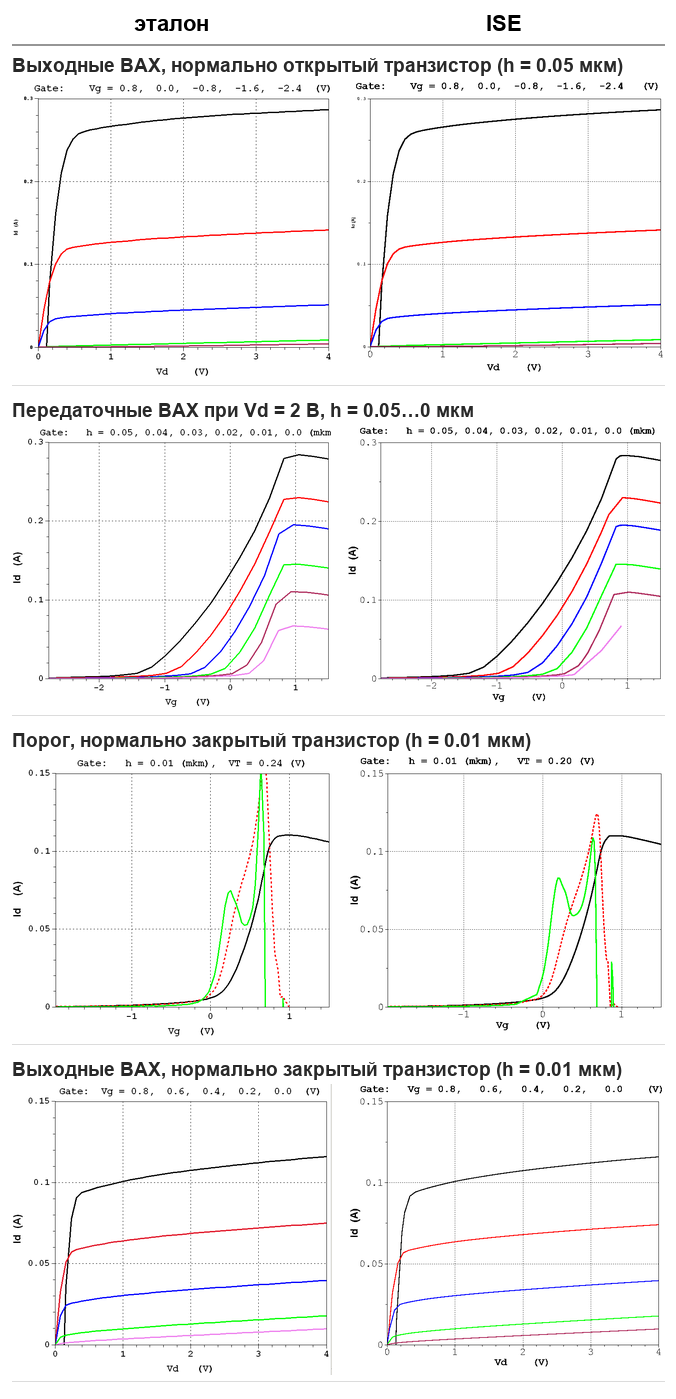

In [8]:
print("построено:", mf.figures())
mf.comparison_grid()
display(Image(os.path.join(LAB, "results", "сравнение.png")))

### Вывод

_(режимы нормально открытого и нормально закрытого транзистора, зависимость тока от h, пороговое напряжение)_